# Variational iPEPS optimization: the Heisenberg model

- Find a ground-state approximation for the square-lattice spin-$\tfrac12$ antiferromagnet, with $J=1$:

  $$
  H=\sum_{\langle ij\rangle}\mathbf S_i\cdot\mathbf S_j.
  $$

- The main task is to define the energy per site (the loss function).
  [YASTN](https://yastn.github.io/yastn/fpeps/environment_ctm.html) supplies CTMRG and differentiable measurements; PyTorch supplies L-BFGS.
- The workflow is: **PEPS → CTMRG → energy → gradient → parameter update**.

- Several well-developed PEPS libraries offer complementary strengths:

  - [PEPSKit.jl](https://quantumkithub.github.io/PEPSKit.jl/stable/) (Julia): **Abelian and non-Abelian symmetric tensors**, including $SU(2)$, through TensorKit.
    Its [broad algorithm coverage](https://arxiv.org/abs/2605.19960) includes CTMRG, boundary-MPS contractions, variational optimization, time evolution, and finite-temperature simulations.

  - [peps-torch](https://github.com/jurajHasik/peps-torch) + [YASTN](https://yastn.github.io/yastn/) (Python/PyTorch): block-sparse tensor algebra with native symmetry support restricted to **Abelian groups**, such as $\mathbb Z_2$ and $U(1)$.
    YASTN also supports [multi-GPU CTMRG](https://yastn.github.io/yastn/fpeps/fixed_point.html#running-on-several-devices-single-node-multi-gpu) and [distributed tensor contractions](https://yastn.github.io/yastn/tensor/large_contractions.html), including automatic differentiation.

  - [variPEPS](https://varipeps.readthedocs.io/en/stable/general.html) (Python/JAX): **triangular-lattice CTMRG** and **split CTMRG**, alongside variational optimization and mappings for other lattice geometries.
    The [Python tensor implementation](https://github.com/variPEPS/variPEPS_Python/blob/main/varipeps/peps/tensor.py) uses dense arrays, with JAX providing JIT compilation and GPU acceleration.


In [7]:
import matplotlib.pyplot as plt
import torch
import yastn
import yastn.tn.fpeps as fpeps

## 1. Initialize the iPEPS

- Use two independent tensors, $A$ and $B$, to allow antiferromagnetic order:

  ```text
  A B A B
  B A B A
  A B A B
  ```

- Start near the Néel state $|\uparrow\downarrow\uparrow\downarrow\cdots\rangle$, with noise to allow entanglement.
- Each tensor has legs **(up, left, down, right, physical)**.
  We use dense tensors to focus on optimization, with virtual dimension $D=2$ and CTM boundary dimension $\chi=8$.

In [23]:
torch.set_num_threads(4)
D, chi = 2, 8  # Small values for a quick demonstration.
ops = yastn.operators.Spin12(
    sym="dense", backend="torch", default_dtype="float64"
)
torch.manual_seed(7)

psi = fpeps.Peps(fpeps.CheckerboardLattice())
for site, spin in zip(psi.sites(), (0, 1)):
    # Start near |up, down, up, down, ...>, with noise to allow entanglement.
    data = 0.1 * torch.randn(D, D, D, D, 2, dtype=torch.float64)
    data[..., spin] += 1
    A = yastn.Tensor(ops.config, s=(1, 1, -1, -1, 1))
    # Leg order: (up, left, down, right, physical).
    A.set_block(Ds=data.shape, val=data / data.norm())
    A.requires_grad_()
    psi[site] = A

## 2. Define the energy

- Write each bond term using real spin matrices:

  $$
  \mathbf S_i\cdot\mathbf S_j
  =S_i^zS_j^z+\frac12(S_i^+S_j^-+S_i^-S_j^+).
  $$

- `psi` is the PEPS, `env` its CTM environment, and `ops` supplies the spin matrices.
- `env.measure_nn(O, P)` returns the normalized expectation $\langle O_iP_j\rangle$ for each distinct nearest-neighbor bond.
- Sum the bond energies and divide by the number of sites in the unit cell.
  Our checkerboard cell contains **two sites and four bonds**, counting each bond once.

In [22]:
def energy_per_site(psi, env, ops):
    """Sum each nearest-neighbor bond once, then divide by the site count."""
    # S_i . S_j = Sz_i Sz_j + (S+_i S-_j + S-_i S+_j) / 2.
    zz = env.measure_nn(ops.sz(), ops.sz())
    pm = env.measure_nn(ops.sp(), ops.sm())
    mp = env.measure_nn(ops.sm(), ops.sp())
    energy = sum(zz[bond] + (pm[bond] + mp[bond]) / 2 for bond in psi.bonds())
    return energy / len(psi.sites())

## 3. Let the packages optimize the tensors

- Expose the tensors' Torch data to L-BFGS.
- Supply a **closure**: a function that evaluates the energy and its gradient for the current tensors.
  Each call builds a fresh CTM environment. `backward()` differentiates through both CTMRG and the measurements.
- L-BFGS chooses the parameter updates and may call the closure several times during a line search.
- Construct the optimizer once to preserve its L-BFGS history. With `max_iter=1`, the outer loop controls the iterations; `max_eval=25` allows multiple line-search trials per call.

In [24]:
# Tensor.data exposes the Torch parameters stored by YASTN.
parameters = [psi[site].data for site in psi.sites()]
optimizer = torch.optim.LBFGS(
    parameters, max_iter=1, max_eval=25, line_search_fn="strong_wolfe"
)
ctm_options = {
    "opts_svd": {"D_total": chi},
    "max_sweeps": 80,
    "corner_tol": 1e-8,
}

def closure():
    """L-BFGS calls this to obtain the energy and its gradient."""
    optimizer.zero_grad()
    env = fpeps.EnvCTM(psi, init="eye")
    env.ctmrg_(**ctm_options)
    energy = energy_per_site(psi, env, ops)
    energy.backward()  # Differentiate through measurements AND CTMRG.
    return energy

# Reuse the optimizer so its L-BFGS history persists between steps.
energies = []
for step in range(20):
    energy = optimizer.step(closure)  # Energy before this update.
    energies.append(energy.item())
    print(f"Step {step + 1:2d}: starting energy = {energy.item():.8f}")

Step  1: starting energy = -0.49929052
Step  2: starting energy = -0.50160907
Step  3: starting energy = -0.50971288
Step  4: starting energy = -0.55223549
Step  5: starting energy = -0.56116398
Step  6: starting energy = -0.58260091
Step  7: starting energy = -0.61099694
Step  8: starting energy = -0.63124198
Step  9: starting energy = -0.65156809
Step 10: starting energy = -0.65388805
Step 11: starting energy = -0.65912595
Step 12: starting energy = -0.65934327
Step 13: starting energy = -0.65955754
Step 14: starting energy = -0.65977413
Step 15: starting energy = -0.65989496
Step 16: starting energy = -0.65997938
Step 17: starting energy = -0.66004675
Step 18: starting energy = -0.66007678
Step 19: starting energy = -0.66013919
Step 20: starting energy = -0.66018044


## 4. Inspect the result

- Recompute the energy after the last update and check that CTMRG converged.
- Compare with the Néel product-state energy, $e=-1/2$ per site.
- Record the starting energy returned by each `.step()` call. The final measurement adds the energy after the last update.
- Plot these outer-loop states, excluding trial states from the line search.
- These small $D$ and $\chi$ are for demonstration. Increase them and check CTMRG and optimization convergence for quantitative results.

Initial energy per site: -0.49929052
Final energy per site:   -0.66020069
Final CTMRG converged: True (21 sweeps)


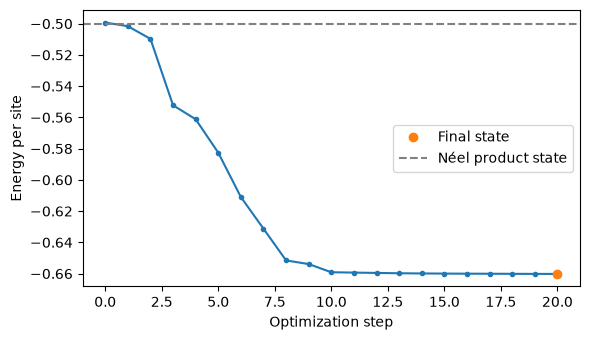

In [25]:
# Measure the final state after the last parameter update.
with torch.no_grad():
    env = fpeps.EnvCTM(psi, init="eye")
    info = env.ctmrg_(**ctm_options)
    final_energy = energy_per_site(psi, env, ops).item()

print(f"Initial energy per site: {energies[0]:.8f}")
print(f"Final energy per site:   {final_energy:.8f}")
print(f"Final CTMRG converged: {info.converged} ({info.sweeps} sweeps)")

# Plot the outer-loop states, including the energy after the last update.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(len(energies) + 1), energies + [final_energy], "o-", ms=3)
ax.plot(len(energies), final_energy, "o", label="Final state")
ax.axhline(-0.5, color="gray", ls="--", label="Néel product state")
ax.set(xlabel="Optimization step", ylabel="Energy per site")
ax.legend()
fig.tight_layout()
plt.show()